# 02. Audio Preprocessing and Multi-Scale Window Slicing

This notebook preprocesses the raw Philippine Eagle audio recordings into standardized, fixed-duration snippets for model training and transfer learning:
1. Filters audio to only include the 59 recordings with verified annotation tables.
2. Extracts metadata from `raw-metadata.csv`, including recording `site` (State) and `age_sex`.
3. Discards any window that overlaps with noise marked as `Unnecessary`.
4. **5.0-Second Preprocessing**: Slices audio into 5.0s windows with a 2.0s hop at 22,050 Hz mono (exported to `data/preprocessed/5-seconds/audios/` and `data/preprocessed/5-seconds/metadata.csv`).
5. **3.0-Second Preprocessing**: Slices audio into 3.0s windows with a 1.5s hop (50% overlap) at 22,050 Hz mono (exported to `data/preprocessed/3-seconds/audios/` and `data/preprocessed/3-seconds/metadata.csv`).
6. Assigns binary labels (`is_eagle = True` / `label = 1` if call overlap >= 50%).
7. Implements caching guards to skip slicing if files already exist in destination folders.
8. Provides side-by-side comparative analysis and visualizations saved to `outputs/figures/`.

## 1. Imports and Configuration

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "02-preprocess"

# Preprocessing parameters
TARGET_SR = 22050           # Resample to 22.05 kHz mono
WINDOW_SIZE_5S = 5.0        # 5.0-second window
HOP_SIZE_5S = 2.0           # 2.0-second hop (3.0s overlap)
WINDOW_SIZE_3S = 3.0        # 3.0-second window (standard for BirdNET)
HOP_SIZE_3S = 1.5           # 1.5-second hop (1.5s / 50% overlap)
CALL_OVERLAP_THRESH = 0.50  # Overlap threshold: >= 50% of call duration in window

# Directory paths
CURRENT_PATH = Path.cwd()
PROJECT_ROOT = CURRENT_PATH if (CURRENT_PATH / "data").exists() else CURRENT_PATH.parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
AUDIO_DIR = RAW_DIR / "audios"
TABLES_DIR = RAW_DIR / "selectionTables"
RAW_META_PATH = RAW_DIR / "raw-metadata.csv"

PREPROCESSED_DIR = DATA_DIR / "preprocessed"

# 5-second directory paths
DIR_5S = PREPROCESSED_DIR / "5-seconds"
OUTPUT_AUDIO_5S = DIR_5S / "audios"
METADATA_5S_PATH = DIR_5S / "metadata.csv"

# 3-second directory paths
DIR_3S = PREPROCESSED_DIR / "3-seconds"
OUTPUT_AUDIO_3S = DIR_3S / "audios"
METADATA_3S_PATH = DIR_3S / "metadata.csv"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

# Ensure output directories exist
OUTPUT_AUDIO_5S.mkdir(parents=True, exist_ok=True)
OUTPUT_AUDIO_3S.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:         {PROJECT_ROOT}")
print(f"Raw audio dir:        {AUDIO_DIR}")
print(f"Selection tables dir: {TABLES_DIR}")
print(f"5-second audio dir:   {OUTPUT_AUDIO_5S}")
print(f"3-second audio dir:   {OUTPUT_AUDIO_3S}")
print(f"Figures output dir:   {FIGURES_DIR}")
print(f"Target sample rate:   {TARGET_SR} Hz")
print(f"5s Window / Hop:      {WINDOW_SIZE_5S}s / {HOP_SIZE_5S}s")
print(f"3s Window / Hop:      {WINDOW_SIZE_3S}s / {HOP_SIZE_3S}s")
print(f"Call overlap thresh:  {CALL_OVERLAP_THRESH * 100:.0f}%")

Project root:         /home/fumei/Documents/MachineLearning/EagleSoundClassification
Raw audio dir:        /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/audios
Selection tables dir: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/selectionTables
5-second audio dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/audios
3-second audio dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/audios
Figures output dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures
Target sample rate:   22050 Hz
5s Window / Hop:      5.0s / 2.0s
3s Window / Hop:      3.0s / 1.5s
Call overlap thresh:  50%


## 2. Load Raw Metadata and Catalog Lookup

In [2]:
# Load raw metadata and build lookup for site and age/sex
df_raw_meta = pd.read_csv(RAW_META_PATH)
df_raw_meta["ML Catalog Number"] = df_raw_meta["ML Catalog Number"].astype(str)

meta_lookup = df_raw_meta.set_index("ML Catalog Number").to_dict("index")

print(f"Loaded raw metadata: {len(df_raw_meta)} catalog entries.")

# Scan audio files and selection tables
all_audio_files = sorted(AUDIO_DIR.glob("*.wav"))
all_table_files = sorted(TABLES_DIR.glob("*.txt"))

audio_dict = {f.stem: f for f in all_audio_files}
table_dict = {f.stem: f for f in all_table_files}

# Strictly retain only audio files with matching selection tables
valid_stems = sorted(list(set(audio_dict.keys()) & set(table_dict.keys())))

print("=" * 60)
print(f"Total audio files found:          {len(all_audio_files)}")
print(f"Total selection tables found:     {len(all_table_files)}")
print(f"Valid paired files to preprocess: {len(valid_stems)}")
print("=" * 60)

Loaded raw metadata: 60 catalog entries.
Total audio files found:          59
Total selection tables found:     59
Valid paired files to preprocess: 59


## 3. Helper Functions for Annotation Parsing and Slicing

In [3]:
def extract_catalog_number(stem: str) -> str:
    """Extract numeric catalog digits from filename stem."""
    match = re.search(r"\d+", stem)
    return match.group(0) if match else ""


def parse_selection_table(table_path: Path):
    """Parse selection table into eagle calls, unnecessary noise intervals, and ambiguous intervals."""
    df = pd.read_csv(table_path, sep="\t")
    df.columns = [c.strip() for c in df.columns]

    eagle_calls = []
    unnecessary = []
    ambiguous = []

    for _, row in df.iterrows():
        b = float(row["Begin Time (s)"])
        e = float(row["End Time (s)"])
        sel_id = int(row["Selection"])
        raw_type = str(row["Type"]).strip()

        # Check for unnecessary noise variations
        if re.search(r"un+ec+es+", raw_type, re.IGNORECASE):
            unnecessary.append((b, e))
        elif re.search(r"ambiguous", raw_type, re.IGNORECASE):
            ambiguous.append((b, e))
        elif re.search(r"PhilEagle", raw_type, re.IGNORECASE):
            c_type = "PhilEagle_long" if "long" in raw_type.lower() else "PhilEagle_short"
            eagle_calls.append({
                "selection_id": sel_id,
                "call_type": c_type,
                "begin": b,
                "end": e,
                "duration": max(0.0, e - b)
            })

    return eagle_calls, unnecessary, ambiguous


def compute_interval_overlap(start1: float, end1: float, start2: float, end2: float) -> float:
    """Calculate temporal overlap duration between two time intervals [start1, end1] and [start2, end2]."""
    return max(0.0, min(end1, end2) - max(start1, start2))


def slice_audio_dataset(
    stems,
    audio_map,
    table_map,
    meta_lookup_dict,
    window_size: float,
    hop_size: float,
    target_sr: int,
    call_overlap_thresh: float,
    output_audio_dir: Path,
    relative_dir_name: str
):
    """
    Slices raw audio recordings into fixed-duration windows, applying noise filtering and annotation labels.
    """
    metadata_records = []
    total_evaluated = 0
    total_unnecessary_discarded = 0

    win_samples = int(window_size * target_sr)
    hop_samples = int(hop_size * target_sr)

    print(f"Starting window slicing (Window: {window_size}s, Hop: {hop_size}s) for {len(stems)} recordings...")

    for stem in tqdm(stems, desc=f"Slicing {window_size}s Clips"):
        audio_path = audio_map[stem]
        table_path = table_map[stem]

        # Retrieve metadata lookup
        cat_num = extract_catalog_number(stem)
        rec_meta = meta_lookup_dict.get(cat_num, {})
        site = rec_meta.get("State", "Unknown")
        age_sex = rec_meta.get("Age/Sex", "Unknown")

        # Parse annotations
        eagle_calls, unnecessary_intervals, ambiguous_intervals = parse_selection_table(table_path)

        # Load and resample audio
        y, sr = librosa.load(audio_path, sr=target_sr, mono=True)
        total_audio_samples = len(y)

        # Slide window (if recording is shorter than window size, retain unpadded as a single slice)
        if total_audio_samples < win_samples:
            window_ranges = [(0, total_audio_samples)]
        else:
            window_ranges = [
                (start_idx, start_idx + win_samples)
                for start_idx in range(0, total_audio_samples - win_samples + 1, hop_samples)
            ]

        for start_idx, end_idx in window_ranges:
            total_evaluated += 1
            w_start = start_idx / target_sr
            w_end = end_idx / target_sr
            slice_duration = round(w_end - w_start, 2)

            # Check overlap with Unnecessary noise (discard completely)
            is_unnecessary = any(
                compute_interval_overlap(w_start, w_end, u_b, u_e) > 0.001
                for u_b, u_e in unnecessary_intervals
            )
            if is_unnecessary:
                total_unnecessary_discarded += 1
                continue

            # Check overlap with confirmed eagle calls
            matching_calls = []
            for call in eagle_calls:
                if call["duration"] <= 0:
                    continue
                overlap_sec = compute_interval_overlap(w_start, w_end, call["begin"], call["end"])
                overlap_ratio = overlap_sec / call["duration"]
                if overlap_ratio >= call_overlap_thresh:
                    matching_calls.append({
                        "selection_id": call["selection_id"],
                        "call_type": call["call_type"],
                        "overlap_sec": overlap_sec,
                        "overlap_ratio": overlap_ratio
                    })

            # Check overlap with ambiguous calls
            has_ambiguous = any(
                compute_interval_overlap(w_start, w_end, a_b, a_e) > 0.001
                for a_b, a_e in ambiguous_intervals
            )

            # Determine target label and attributes
            if len(matching_calls) > 0:
                is_eagle = True
                label = 1
                call_types = ";".join(sorted(list({c["call_type"] for c in matching_calls})))
                call_ids = ";".join([str(c["selection_id"]) for c in matching_calls])
                call_uid = ";".join([f"{stem}_call_{c['selection_id']}" for c in matching_calls])
                call_overlap_ratio = round(max(c["overlap_ratio"] for c in matching_calls), 4)
            else:
                is_eagle = False
                label = 0
                call_types = "none"
                call_ids = "none"
                call_uid = "none"
                call_overlap_ratio = 0.0

            # Save audio slice (unpadded)
            slice_filename = f"{stem}_{w_start:07.1f}_{w_end:07.1f}.wav"
            slice_filepath = output_audio_dir / slice_filename
            audio_slice = y[start_idx:end_idx]
            sf.write(slice_filepath, audio_slice, target_sr, subtype="PCM_16")

            # Record metadata
            relative_filepath = f"{relative_dir_name}/{slice_filename}"
            metadata_records.append({
                "file_name": slice_filename,
                "file_path": relative_filepath,
                "source_audio": audio_path.name,
                "site": site,
                "age_sex": age_sex,
                "start_time": round(w_start, 2),
                "end_time": round(w_end, 2),
                "duration": slice_duration,
                "sample_rate": target_sr,
                "is_eagle": is_eagle,
                "label": label,
                "call_types": call_types,
                "call_ids": call_ids,
                "call_uid": call_uid,
                "call_overlap_ratio": call_overlap_ratio,
                "has_ambiguous": has_ambiguous
            })

    print(f"\nCompleted {window_size}s slicing!")
    print(f"Total evaluated windows:       {total_evaluated}")
    print(f"Discarded unnecessary windows: {total_unnecessary_discarded}")
    print(f"Final valid saved windows:     {len(metadata_records)}")
    print(f"Distinct recordings processed: {len({r['source_audio'] for r in metadata_records})}")

    return metadata_records

## 4. Preprocessing: 5.0-Second Windows

### 4.1. Slice 5.0-Second Audio Snippets

In [4]:
# Caching guard: check if 5-second output directory already contains processed files
existing_5s = list(OUTPUT_AUDIO_5S.glob("*.wav"))

if len(existing_5s) > 0 and METADATA_5S_PATH.exists():
    print(f"Output directory '{OUTPUT_AUDIO_5S}' already contains {len(existing_5s)} files and metadata exists.")
    print("Skipping 5.0s slicing. To re-process, delete the files in data/preprocessed/5-seconds/audios/ first.")
    df_metadata_5s = pd.read_csv(METADATA_5S_PATH)
else:
    records_5s = slice_audio_dataset(
        stems=valid_stems,
        audio_map=audio_dict,
        table_map=table_dict,
        meta_lookup_dict=meta_lookup,
        window_size=WINDOW_SIZE_5S,
        hop_size=HOP_SIZE_5S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_5S,
        relative_dir_name="data/preprocessed/5-seconds/audios"
    )
    df_metadata_5s = pd.DataFrame(records_5s)

Starting window slicing (Window: 5.0s, Hop: 2.0s) for 59 recordings...


Slicing 5.0s Clips: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 59/59 [00:15<00:00,  3.84it/s]


Completed 5.0s slicing!
Total evaluated windows:       7183
Discarded unnecessary windows: 672
Final valid saved windows:     6511
Distinct recordings processed: 59


### 4.2. Save 5.0-Second Preprocessed Metadata

In [5]:
# Save 5-second metadata to CSV
if not METADATA_5S_PATH.exists() or len(existing_5s) == 0:
    df_metadata_5s.to_csv(METADATA_5S_PATH, index=False)
    print(f"Successfully saved 5s metadata to {METADATA_5S_PATH}")
else:
    print(f"Loaded existing 5s metadata from {METADATA_5S_PATH}")

print("=" * 60)
print(f"Total 5.0s sliced audio records:     {len(df_metadata_5s)}")
print(f"Total unique source recordings (5s): {df_metadata_5s['source_audio'].nunique()}")
print("=" * 60)
df_metadata_5s.head(5)

Successfully saved 5s metadata to /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/metadata.csv
Total 5.0s sliced audio records:     6511
Total unique source recordings (5s): 59


,file_name,file_path,source_audio,site,age_sex,start_time,end_time,duration,sample_rate,is_eagle,label,call_types,call_ids,call_uid,call_overlap_ratio,has_ambiguous
0,converted_135598_00006.0_00011.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,6.0,11.0,5.0,22050,True,1,PhilEagle_long,2;3,converted_135598_call_2;converted_135598_call_3,1.0,False
1,converted_135598_00008.0_00013.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,8.0,13.0,5.0,22050,True,1,PhilEagle_long,3;4,converted_135598_call_3;converted_135598_call_4,1.0,False
2,converted_135598_00010.0_00015.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,10.0,15.0,5.0,22050,True,1,PhilEagle_long,4;5,converted_135598_call_4;converted_135598_call_5,1.0,False
3,converted_135598_00012.0_00017.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,12.0,17.0,5.0,22050,True,1,PhilEagle_long,5;6;7,converted_135598_call_5;converted_135598_call_...,1.0,False
4,converted_135598_00014.0_00019.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,14.0,19.0,5.0,22050,True,1,PhilEagle_long,6;7;8,converted_135598_call_6;converted_135598_call_...,1.0,False


### 4.3. Analyze 5.0-Second Class and Site Distributions

In [6]:
# Class balance analysis for 5-second clips
total_slices_5s = len(df_metadata_5s)
eagle_slices_5s = (df_metadata_5s["label"] == 1).sum()
background_slices_5s = (df_metadata_5s["label"] == 0).sum()

pct_eagle_5s = (eagle_slices_5s / total_slices_5s) * 100 if total_slices_5s > 0 else 0
pct_background_5s = (background_slices_5s / total_slices_5s) * 100 if total_slices_5s > 0 else 0
imbalance_ratio_5s = background_slices_5s / eagle_slices_5s if eagle_slices_5s > 0 else 0

ambiguous_in_background_5s = ((df_metadata_5s["label"] == 0) & (df_metadata_5s["has_ambiguous"])).sum()

print("=" * 60)
print("5.0-SECOND CLASS BALANCE & LABEL DISTRIBUTION")
print("=" * 60)
print(f"Total Preprocessed Slices:         {total_slices_5s}")
print(f"Eagle Call Slices (Class 1):       {eagle_slices_5s} ({pct_eagle_5s:.2f}%)")
print(f"Background Slices (Class 0):       {background_slices_5s} ({pct_background_5s:.2f}%)")
print(f"Class Imbalance Ratio (Neg:Pos):   {imbalance_ratio_5s:.2f} : 1")
print(f"Background Slices with Ambiguous:   {ambiguous_in_background_5s}")
print("=" * 60)

# Cross-tabulate site vs target label
site_crosstab_5s = pd.crosstab(df_metadata_5s["site"], df_metadata_5s["label"], margins=True)
site_crosstab_5s.columns = ["No Eagle (0)", "Eagle (1)", "Total"]
print("\nGeographic Site (State) Distribution (5s):")
print(site_crosstab_5s)

5.0-SECOND CLASS BALANCE & LABEL DISTRIBUTION
Total Preprocessed Slices:         6511
Eagle Call Slices (Class 1):       2963 (45.51%)
Background Slices (Class 0):       3548 (54.49%)
Class Imbalance Ratio (Neg:Pos):   1.20 : 1
Background Slices with Ambiguous:   110

Geographic Site (State) Distribution (5s):
                  No Eagle (0)  Eagle (1)  Total
site                                            
Agusan del Sur               0          2      2
Bukidnon                    16        106    122
Cotabato                  1286       1224   2510
Davao Oriental              30         23     53
Davao del Sur             2216       1607   3823
Misamis Oriental             0          1      1
All                       3548       2963   6511


## 5. Preprocessing: 3.0-Second Windows

### 5.1. Slice 3.0-Second Audio Snippets

In [7]:
# Caching guard: check if 3-second output directory already contains processed files
existing_3s = list(OUTPUT_AUDIO_3S.glob("*.wav"))

if len(existing_3s) > 0 and METADATA_3S_PATH.exists():
    print(f"Output directory '{OUTPUT_AUDIO_3S}' already contains {len(existing_3s)} files and metadata exists.")
    print("Skipping 3.0s slicing. To re-process, delete the files in data/preprocessed/3-seconds/audios/ first.")
    df_metadata_3s = pd.read_csv(METADATA_3S_PATH)
else:
    records_3s = slice_audio_dataset(
        stems=valid_stems,
        audio_map=audio_dict,
        table_map=table_dict,
        meta_lookup_dict=meta_lookup,
        window_size=WINDOW_SIZE_3S,
        hop_size=HOP_SIZE_3S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_3S,
        relative_dir_name="data/preprocessed/3-seconds/audios"
    )
    df_metadata_3s = pd.DataFrame(records_3s)

Starting window slicing (Window: 3.0s, Hop: 1.5s) for 59 recordings...


Slicing 3.0s Clips: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 59/59 [00:16<00:00,  3.64it/s]



Completed 3.0s slicing!
Total evaluated windows:       9650
Discarded unnecessary windows: 844
Final valid saved windows:     8806
Distinct recordings processed: 59


### 5.2. Save 3.0-Second Preprocessed Metadata

In [8]:
# Save 3-second metadata to CSV
if not METADATA_3S_PATH.exists() or len(existing_3s) == 0:
    df_metadata_3s.to_csv(METADATA_3S_PATH, index=False)
    print(f"Successfully saved 3s metadata to {METADATA_3S_PATH}")
else:
    print(f"Loaded existing 3s metadata from {METADATA_3S_PATH}")

print("=" * 60)
print(f"Total 3.0s sliced audio records:     {len(df_metadata_3s)}")
print(f"Total unique source recordings (3s): {df_metadata_3s['source_audio'].nunique()}")
print("=" * 60)
df_metadata_3s.head(5)

Successfully saved 3s metadata to /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/metadata.csv
Total 3.0s sliced audio records:     8806
Total unique source recordings (3s): 59


,file_name,file_path,source_audio,site,age_sex,start_time,end_time,duration,sample_rate,is_eagle,label,call_types,call_ids,call_uid,call_overlap_ratio,has_ambiguous
0,converted_135598_00004.5_00007.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,4.5,7.5,3.0,22050,True,1,PhilEagle_long,2,converted_135598_call_2,1.0000,False
1,converted_135598_00006.0_00009.0.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,6.0,9.0,3.0,22050,True,1,PhilEagle_long,2;3,converted_135598_call_2;converted_135598_call_3,1.0000,False
2,converted_135598_00007.5_00010.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,7.5,10.5,3.0,22050,True,1,PhilEagle_long,3,converted_135598_call_3,1.0000,False
3,converted_135598_00009.0_00012.0.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,9.0,12.0,3.0,22050,True,1,PhilEagle_long,4,converted_135598_call_4,0.6799,False
4,converted_135598_00010.5_00013.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,10.5,13.5,3.0,22050,True,1,PhilEagle_long,4,converted_135598_call_4,1.0000,False


### 5.3. Analyze 3.0-Second Class and Site Distributions

In [9]:
# Class balance analysis for 3-second clips
total_slices_3s = len(df_metadata_3s)
eagle_slices_3s = (df_metadata_3s["label"] == 1).sum()
background_slices_3s = (df_metadata_3s["label"] == 0).sum()

pct_eagle_3s = (eagle_slices_3s / total_slices_3s) * 100 if total_slices_3s > 0 else 0
pct_background_3s = (background_slices_3s / total_slices_3s) * 100 if total_slices_3s > 0 else 0
imbalance_ratio_3s = background_slices_3s / eagle_slices_3s if eagle_slices_3s > 0 else 0

ambiguous_in_background_3s = ((df_metadata_3s["label"] == 0) & (df_metadata_3s["has_ambiguous"])).sum()

print("=" * 60)
print("3.0-SECOND CLASS BALANCE & LABEL DISTRIBUTION")
print("=" * 60)
print(f"Total Preprocessed Slices:         {total_slices_3s}")
print(f"Eagle Call Slices (Class 1):       {eagle_slices_3s} ({pct_eagle_3s:.2f}%)")
print(f"Background Slices (Class 0):       {background_slices_3s} ({pct_background_3s:.2f}%)")
print(f"Class Imbalance Ratio (Neg:Pos):   {imbalance_ratio_3s:.2f} : 1")
print(f"Background Slices with Ambiguous:   {ambiguous_in_background_3s}")
print("=" * 60)

# Cross-tabulate site vs target label
site_crosstab_3s = pd.crosstab(df_metadata_3s["site"], df_metadata_3s["label"], margins=True)
site_crosstab_3s.columns = ["No Eagle (0)", "Eagle (1)", "Total"]
print("\nGeographic Site (State) Distribution (3s):")
print(site_crosstab_3s)

3.0-SECOND CLASS BALANCE & LABEL DISTRIBUTION
Total Preprocessed Slices:         8806
Eagle Call Slices (Class 1):       3398 (38.59%)
Background Slices (Class 0):       5408 (61.41%)
Class Imbalance Ratio (Neg:Pos):   1.59 : 1
Background Slices with Ambiguous:   146

Geographic Site (State) Distribution (3s):
                  No Eagle (0)  Eagle (1)  Total
site                                            
Agusan del Sur               1          3      4
Bukidnon                    43        130    173
Cotabato                  1921       1488   3409
Davao Oriental              44         29     73
Davao del Sur             3399       1746   5145
Misamis Oriental             0          2      2
All                       5408       3398   8806


## 6. Comparative Analysis and Visualizations

### 6.1. Side-by-Side Slicing Statistics Comparison

In [10]:
# Comparison table between 5s and 3s datasets
comparison_data = {
    "Metric": [
        "Window Duration",
        "Hop Size",
        "Window Overlap",
        "Total Valid Slices",
        "Eagle Call Slices (1)",
        "Background Slices (0)",
        "Eagle Percentage",
        "Imbalance Ratio (Neg:Pos)",
        "Background with Ambiguous",
        "Unique Source Recordings"
    ],
    "5.0-Second Pipeline": [
        "5.0 s",
        "2.0 s",
        "3.0 s (60%)",
        f"{total_slices_5s:,}",
        f"{eagle_slices_5s:,}",
        f"{background_slices_5s:,}",
        f"{pct_eagle_5s:.2f}%",
        f"{imbalance_ratio_5s:.2f} : 1",
        f"{ambiguous_in_background_5s:,}",
        f"{df_metadata_5s['source_audio'].nunique()}"
    ],
    "3.0-Second Pipeline": [
        "3.0 s",
        "1.5 s",
        "1.5 s (50%)",
        f"{total_slices_3s:,}",
        f"{eagle_slices_3s:,}",
        f"{background_slices_3s:,}",
        f"{pct_eagle_3s:.2f}%",
        f"{imbalance_ratio_3s:.2f} : 1",
        f"{ambiguous_in_background_3s:,}",
        f"{df_metadata_3s['source_audio'].nunique()}"
    ]
}

df_comparison = pd.DataFrame(comparison_data)
print("=" * 70)
print("DATASET COMPARISON: 5.0-SECOND vs. 3.0-SECOND SLICING")
print("=" * 70)
print(df_comparison.to_string(index=False))
print("=" * 70)

DATASET COMPARISON: 5.0-SECOND vs. 3.0-SECOND SLICING
                   Metric 5.0-Second Pipeline 3.0-Second Pipeline
          Window Duration               5.0 s               3.0 s
                 Hop Size               2.0 s               1.5 s
           Window Overlap         3.0 s (60%)         1.5 s (50%)
       Total Valid Slices               6,511               8,806
    Eagle Call Slices (1)               2,963               3,398
    Background Slices (0)               3,548               5,408
         Eagle Percentage              45.51%              38.59%
Imbalance Ratio (Neg:Pos)            1.20 : 1            1.59 : 1
Background with Ambiguous                 110                 146
 Unique Source Recordings                  59                  59


### 6.2. Generate and Save Comparative Class Distribution Visualizations

Saved comparison figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/02-preprocess-5s-vs-3s-distribution-comparison.png


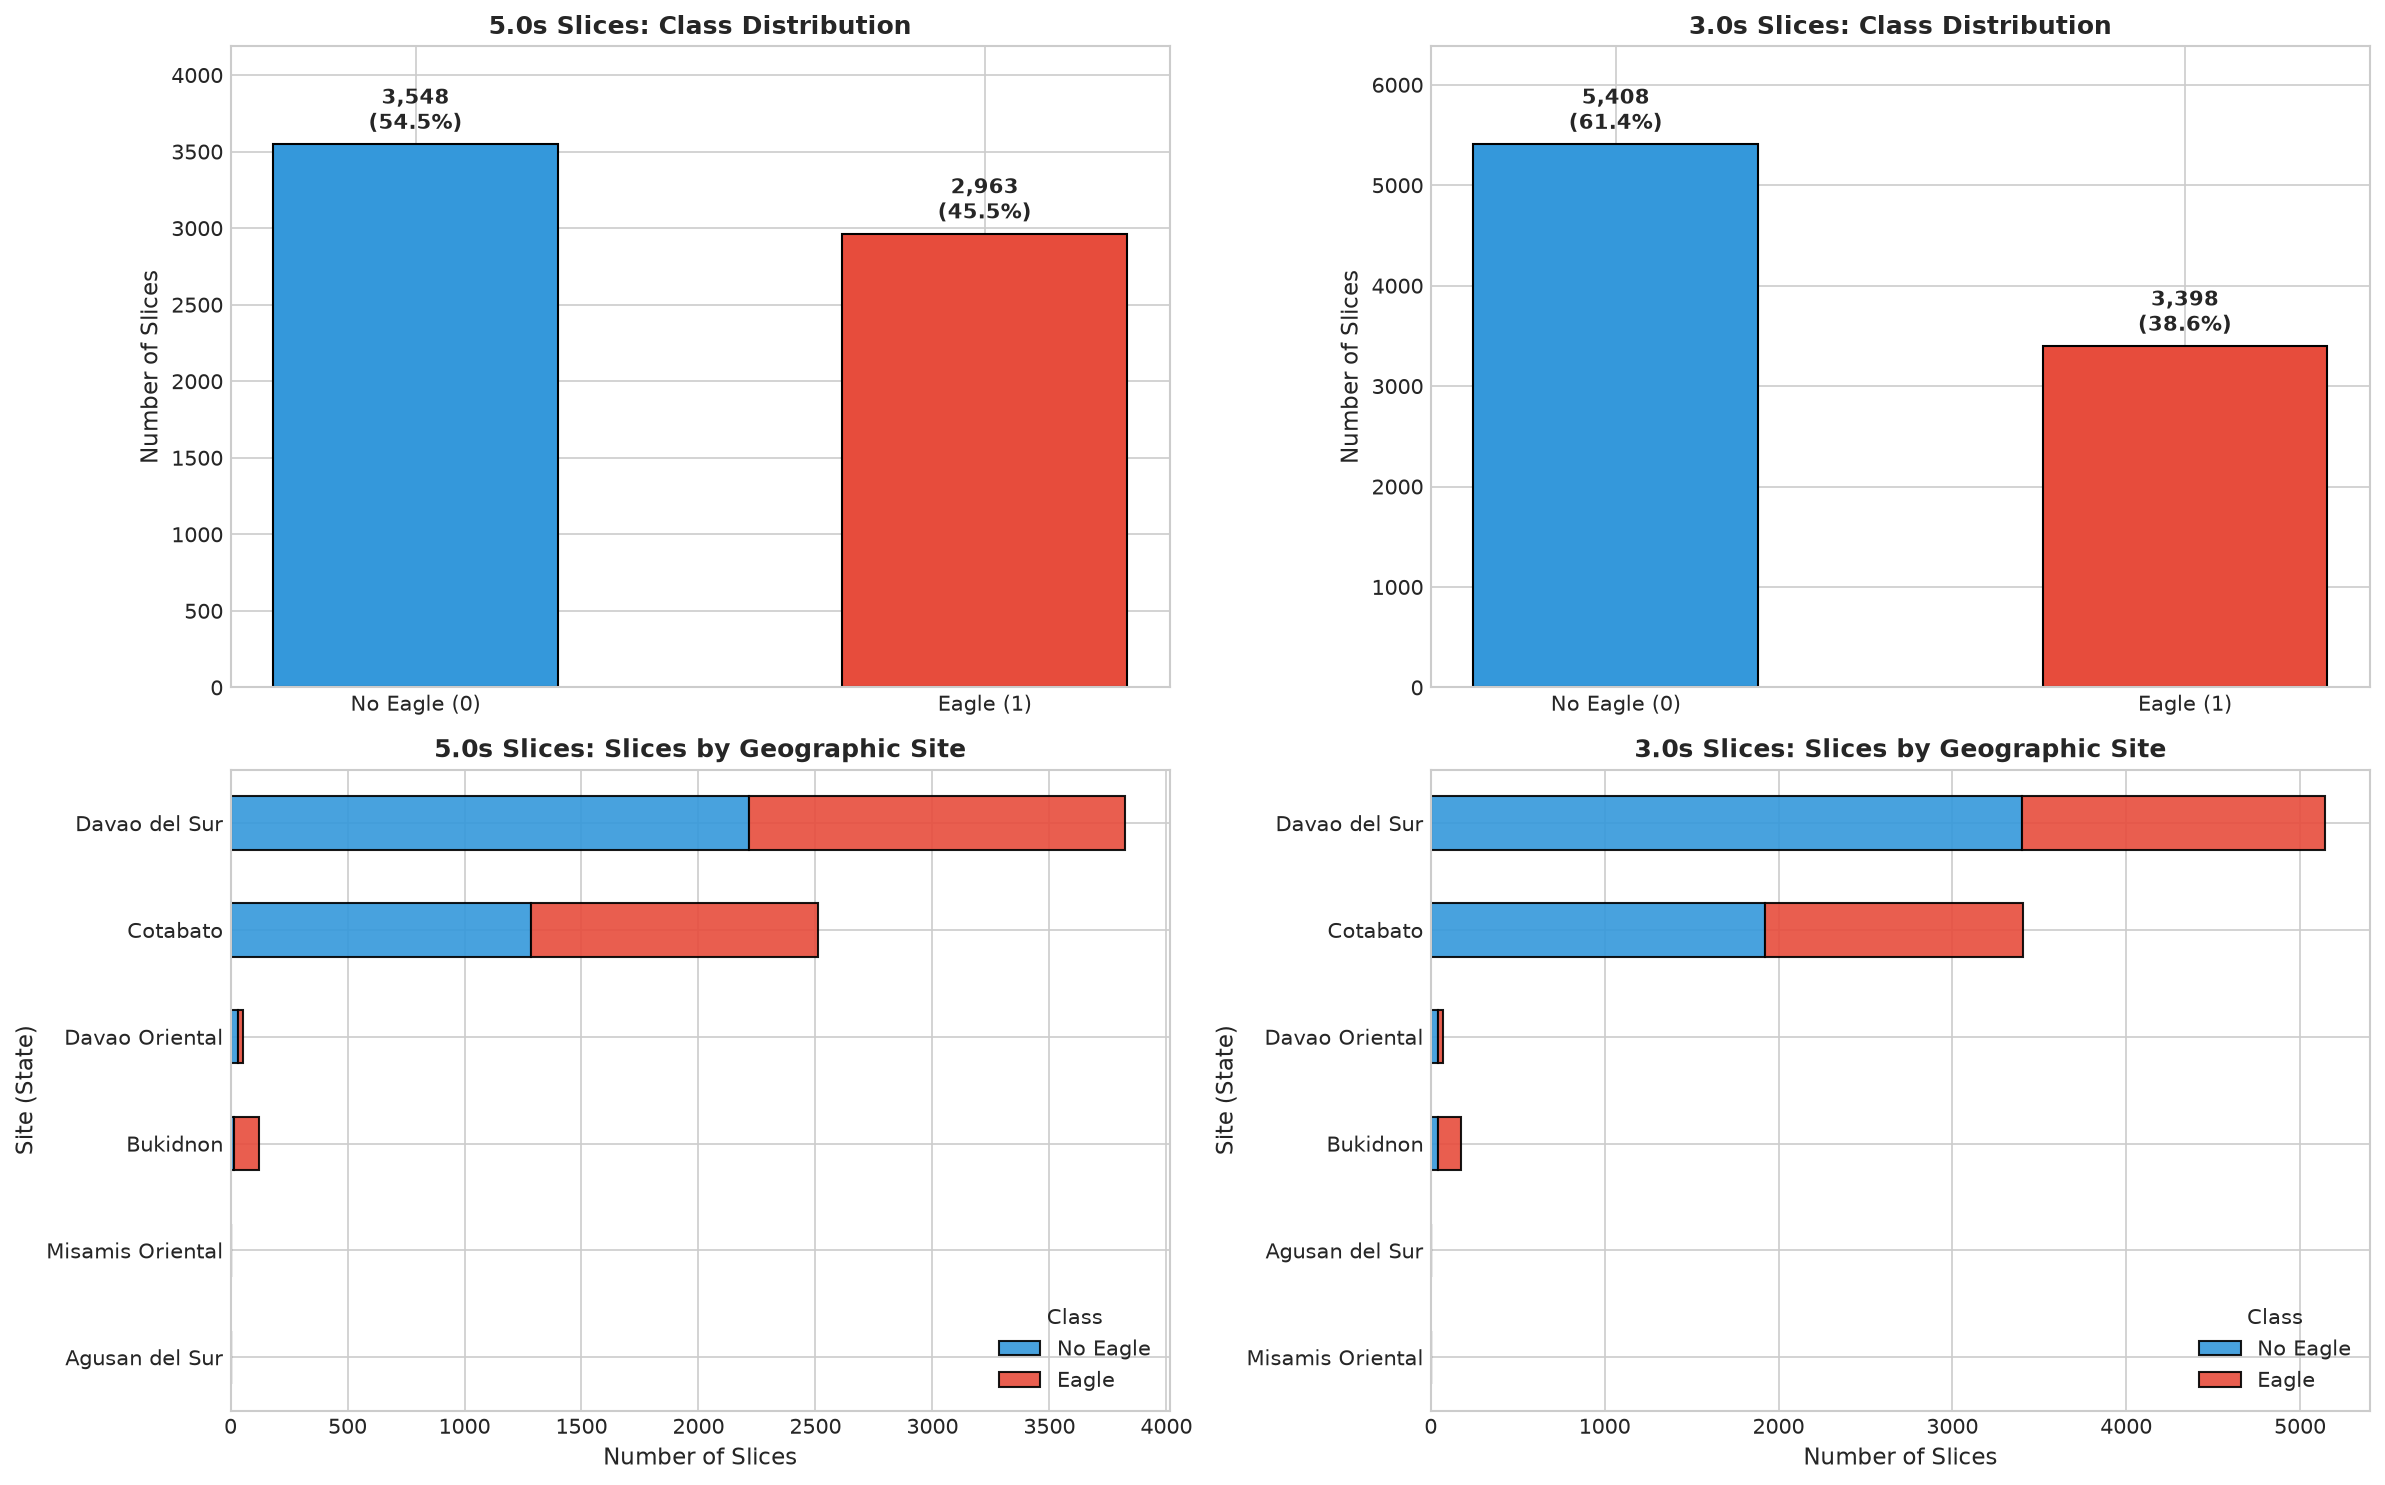

In [11]:
# Comparative visualization of class and site distributions
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel (0, 0): 5s Class Distribution
bars_5s = axes[0, 0].bar(
    ["No Eagle (0)", "Eagle (1)"],
    [background_slices_5s, eagle_slices_5s],
    color=["#3498db", "#e74c3c"], width=0.5, edgecolor="black"
)
for bar in bars_5s:
    h = bar.get_height()
    axes[0, 0].annotate(f"{h:,}\n({h/total_slices_5s*100:.1f}%)",
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontweight="bold")
axes[0, 0].set_title("5.0s Slices: Class Distribution", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Number of Slices")
axes[0, 0].set_ylim(0, max(background_slices_5s, eagle_slices_5s) * 1.18)

# Panel (0, 1): 3s Class Distribution
bars_3s = axes[0, 1].bar(
    ["No Eagle (0)", "Eagle (1)"],
    [background_slices_3s, eagle_slices_3s],
    color=["#3498db", "#e74c3c"], width=0.5, edgecolor="black"
)
for bar in bars_3s:
    h = bar.get_height()
    axes[0, 1].annotate(f"{h:,}\n({h/total_slices_3s*100:.1f}%)",
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontweight="bold")
axes[0, 1].set_title("3.0s Slices: Class Distribution", fontsize=12, fontweight="bold")
axes[0, 1].set_ylabel("Number of Slices")
axes[0, 1].set_ylim(0, max(background_slices_3s, eagle_slices_3s) * 1.18)

# Panel (1, 0): 5s Site Distribution
site_5s_plot = pd.crosstab(df_metadata_5s["site"], df_metadata_5s["label"])
site_5s_plot.columns = ["No Eagle", "Eagle"]
site_5s_plot = site_5s_plot.sort_values(by="No Eagle", ascending=True)
site_5s_plot.plot(kind="barh", stacked=True, color=["#3498db", "#e74c3c"], ax=axes[1, 0], edgecolor="black", alpha=0.9)
axes[1, 0].set_title("5.0s Slices: Slices by Geographic Site", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Number of Slices")
axes[1, 0].set_ylabel("Site (State)")
axes[1, 0].legend(title="Class", loc="lower right")

# Panel (1, 1): 3s Site Distribution
site_3s_plot = pd.crosstab(df_metadata_3s["site"], df_metadata_3s["label"])
site_3s_plot.columns = ["No Eagle", "Eagle"]
site_3s_plot = site_3s_plot.sort_values(by="No Eagle", ascending=True)
site_3s_plot.plot(kind="barh", stacked=True, color=["#3498db", "#e74c3c"], ax=axes[1, 1], edgecolor="black", alpha=0.9)
axes[1, 1].set_title("3.0s Slices: Slices by Geographic Site", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Number of Slices")
axes[1, 1].set_ylabel("Site (State)")
axes[1, 1].legend(title="Class", loc="lower right")

plt.tight_layout()

out_comparison_fig = FIGURES_DIR / f"{NOTEBOOK_ID}-5s-vs-3s-distribution-comparison.png"
fig.savefig(out_comparison_fig, dpi=300, bbox_inches="tight")
print(f"Saved comparison figure: {out_comparison_fig}")
plt.show()

### 6.3. Visualize Call Subtypes and Recording-Level Slice Balance

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/02-preprocess-call-subtypes-and-recordings.png


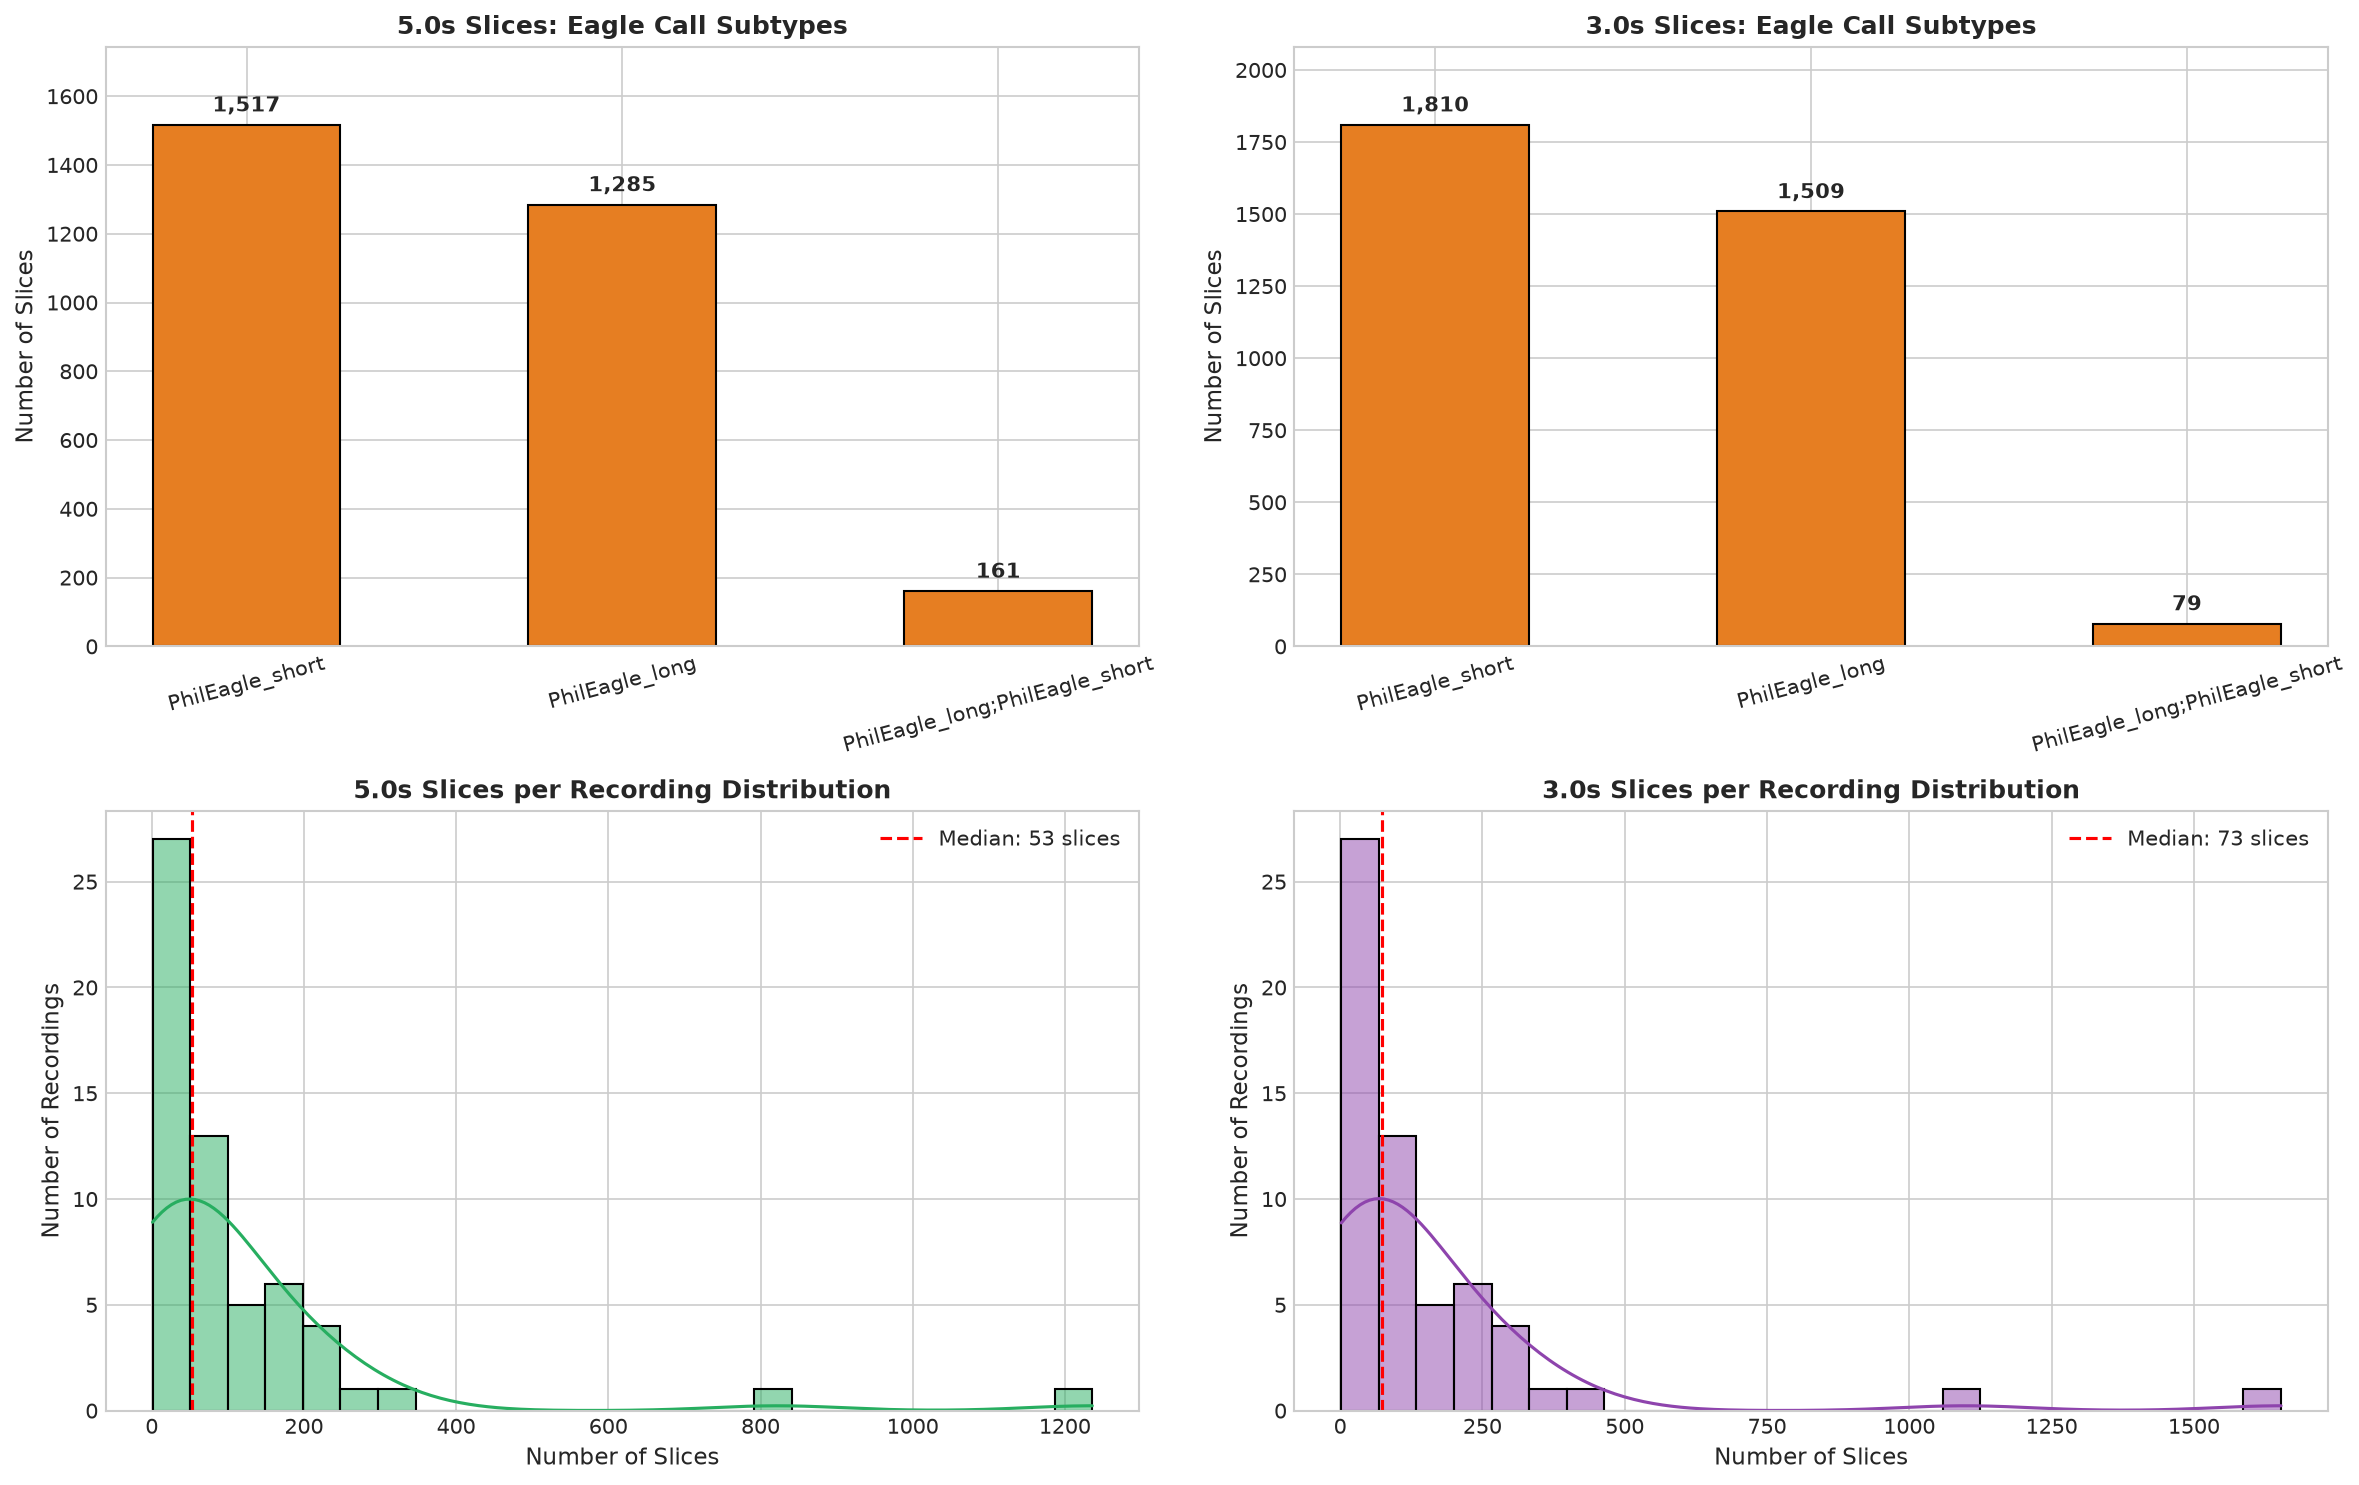

In [12]:
# Multi-panel visualization for call subtypes and slices per recording across both datasets
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel (0, 0): 5s Call Subtypes
pos_5s = df_metadata_5s[df_metadata_5s["is_eagle"]]
subtype_5s = pos_5s["call_types"].value_counts()
axes[0, 0].bar(subtype_5s.index, subtype_5s.values, color="#e67e22", edgecolor="black", width=0.5)
for i, v in enumerate(subtype_5s.values):
    axes[0, 0].annotate(f"{v:,}", xy=(i, v), xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontweight="bold")
axes[0, 0].set_title("5.0s Slices: Eagle Call Subtypes", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Number of Slices")
axes[0, 0].tick_params(axis="x", rotation=15)
axes[0, 0].set_ylim(0, max(subtype_5s.values) * 1.15)

# Panel (0, 1): 3s Call Subtypes
pos_3s = df_metadata_3s[df_metadata_3s["is_eagle"]]
subtype_3s = pos_3s["call_types"].value_counts()
axes[0, 1].bar(subtype_3s.index, subtype_3s.values, color="#e67e22", edgecolor="black", width=0.5)
for i, v in enumerate(subtype_3s.values):
    axes[0, 1].annotate(f"{v:,}", xy=(i, v), xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontweight="bold")
axes[0, 1].set_title("3.0s Slices: Eagle Call Subtypes", fontsize=12, fontweight="bold")
axes[0, 1].set_ylabel("Number of Slices")
axes[0, 1].tick_params(axis="x", rotation=15)
axes[0, 1].set_ylim(0, max(subtype_3s.values) * 1.15)

# Panel (1, 0): 5s Slices per Recording
rec_5s = df_metadata_5s.groupby("source_audio").size()
sns.histplot(rec_5s, bins=25, kde=True, color="#27ae60", ax=axes[1, 0], edgecolor="black")
axes[1, 0].axvline(rec_5s.median(), color="red", linestyle="--",
                   label=f"Median: {rec_5s.median():.0f} slices")
axes[1, 0].set_title("5.0s Slices per Recording Distribution", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Number of Slices")
axes[1, 0].set_ylabel("Number of Recordings")
axes[1, 0].legend()

# Panel (1, 1): 3s Slices per Recording
rec_3s = df_metadata_3s.groupby("source_audio").size()
sns.histplot(rec_3s, bins=25, kde=True, color="#8e44ad", ax=axes[1, 1], edgecolor="black")
axes[1, 1].axvline(rec_3s.median(), color="red", linestyle="--",
                   label=f"Median: {rec_3s.median():.0f} slices")
axes[1, 1].set_title("3.0s Slices per Recording Distribution", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Number of Slices")
axes[1, 1].set_ylabel("Number of Recordings")
axes[1, 1].legend()

plt.tight_layout()

out_subtypes_fig = FIGURES_DIR / f"{NOTEBOOK_ID}-call-subtypes-and-recordings.png"
fig.savefig(out_subtypes_fig, dpi=300, bbox_inches="tight")
print(f"Saved figure: {out_subtypes_fig}")
plt.show()

### 6.4. Pipeline Summary and Downstream Recommendations

In [13]:
# Summary recommendations for downstream models
print("=" * 70)
print("PREPROCESSING PIPELINE SUMMARY & DOWNSTREAM RECOMMENDATIONS")
print("=" * 70)
print("1. Group-Based Splitting:")
print("   - Always split train/val/test using 'source_audio' as the group key.")
print("   - This strictly prevents leakage of identical recording environments.")
print("2. Multi-Scale Model Compatibility:")
print("   - 5.0-second slices (data/preprocessed/5-seconds/):")
print("     Optimized for custom spectrogram architectures (e.g. PCEN CRNN-GRU).")
print("   - 3.0-second slices (data/preprocessed/3-seconds/):")
print("     Native window length for BirdNET transfer learning and bioacoustic foundation models.")
print("3. Negative Data Cleansing:")
print(f"   - 5s background slices with ambiguous annotations: {ambiguous_in_background_5s}")
print(f"   - 3s background slices with ambiguous annotations: {ambiguous_in_background_3s}")
print("   - Filter out 'has_ambiguous == True' when constructing clean training sets.")
print("=" * 70)

PREPROCESSING PIPELINE SUMMARY & DOWNSTREAM RECOMMENDATIONS
1. Group-Based Splitting:
   - Always split train/val/test using 'source_audio' as the group key.
   - This strictly prevents leakage of identical recording environments.
2. Multi-Scale Model Compatibility:
   - 5.0-second slices (data/preprocessed/5-seconds/):
     Optimized for custom spectrogram architectures (e.g. PCEN CRNN-GRU).
   - 3.0-second slices (data/preprocessed/3-seconds/):
     Native window length for BirdNET transfer learning and bioacoustic foundation models.
3. Negative Data Cleansing:
   - 5s background slices with ambiguous annotations: 110
   - 3s background slices with ambiguous annotations: 146
   - Filter out 'has_ambiguous == True' when constructing clean training sets.
